# ChemBed latent-space diagnostics

This notebook is intented to test and check the usual ChemBed molecule generation, and whether using dimmension reduction affects the generation

## 1. Load models and reference actives

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "config.toml").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from config import ExperimentConfig
from EVA import load_activity_oracle
from chemistry.molecules import ParsedMolecules
from chemistry.scaffolds import generic_scaffold_hash
from chemistry.smiles import parse_and_canonical
from evaluation.dimensions import compute_dimension
from evaluation.activity import predict_from_features
from generative import ChemBedVAE, ProjectedVAE
from notebooks.vae_utils import (
    cacher,
    clear_gpu,
    load_reference_actives,
    mol_grid,
    sample_latent,
)

RDLogger.DisableLog("rdApp.*")
SEED = 42
rng = np.random.default_rng(SEED)
CONFIG = ROOT / "config.toml"
DEVICE = "cuda"


/home/bruno/micromamba/envs/eva/lib/python3.12/site-packages/chembed/utils.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [2]:
reference_smiles, reference_scores = load_reference_actives()

print(f"Reference actives: {len(reference_smiles):,}")
print(
    f"P(active): min={reference_scores.min():.3f}  "
    f"median={np.median(reference_scores):.3f}  max={reference_scores.max():.3f}"
)
print(f"Above 0.7: {(reference_scores > 0.7).sum():,}")

Loading activity oracle

TabPFN inference:   0%|          | 0/8 [00:00<?, ?estimator/s]

Reference actives: 2,917
P(active): min=0.287  median=0.916  max=0.999
Above 0.7: 2,584


In [3]:
cfg = ExperimentConfig.from_toml(CONFIG)
model_path = Path(cfg.activity.model_path)
if not model_path.is_absolute():
    cfg.activity.model_path = str(ROOT / model_path)
native = ChemBedVAE(
    model_repo_id=cfg.generative.model_repo_id,
    device=DEVICE,
    latent_dim=cfg.generative.latent_dim,
)
projected = ProjectedVAE(native, ROOT / cfg.pca.path)
pca = projected._pca


print(f"Native latent: {native.latent_dim} dimensions")
print(f"PCA working space: {projected.latent_dim} dimensions")
print(f"PCA explained variance: {pca.explained_variance_ratio_.sum():.4%}")
print(f"PCA whiten=True: {pca.whiten}")

Native latent: 256 dimensions
PCA working space: 95 dimensions
PCA explained variance: 99.0658%
PCA whiten=True: True


In [4]:
z_native_ref = native.encode(reference_smiles, batch_size=256)
z_pca_ref = projected.encode(reference_smiles, batch_size=256)

latent_stats = pd.DataFrame({
    "space": ["native", "pca"],
    "dimensions": [z_native_ref.shape[1], z_pca_ref.shape[1]],
    "mean_norm": [np.linalg.norm(z_native_ref, axis=1).mean(), np.linalg.norm(z_pca_ref, axis=1).mean()],
    "p50_norm": [np.percentile(np.linalg.norm(z_native_ref, axis=1), 50), np.percentile(np.linalg.norm(z_pca_ref, axis=1), 50)],
    "p95_norm": [np.percentile(np.linalg.norm(z_native_ref, axis=1), 95), np.percentile(np.linalg.norm(z_pca_ref, axis=1), 95)],
    "coordinate_mean": [z_native_ref.mean(), z_pca_ref.mean()],
    "coordinate_std": [z_native_ref.std(), z_pca_ref.std()],
})
display(latent_stats)

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, z, label in zip(axes, [z_native_ref, z_pca_ref], ["Native", "PCA"]):
    ax.hist(np.linalg.norm(z, axis=1), bins=40, alpha=0.8)
    ax.set_title(f"{label} reference latent norms")
    ax.set_xlabel("L2 norm")
plt.tight_layout()
plt.show()

,space,dimensions,mean_norm,p50_norm,p95_norm,coordinate_mean,coordinate_std
0,native,256,11.254040,11.182549,12.985584,0.015004,0.705944
1,pca,95,9.254438,9.180739,11.936847,-0.001510,0.962534


## 2. Encode/decode 

In [5]:
def roundtrip_table(model, z, label, indices=None):
    indices = np.arange(len(reference_smiles)) if indices is None else np.asarray(indices)
    decoded = model.decode(z[indices], batch_size=256)
    rows = []
    for i, out in zip(indices, decoded):
        valid, canonical = parse_and_canonical(out)
        source = reference_smiles[i]
        rows.append({
            "space": label,
            "index": int(i),
            "input": source,
            "decoded": out,
            "valid": valid,
            "exact": valid and canonical == source,
            "canonical": canonical,
            "scaffold_retained": valid and generic_scaffold_hash(canonical) == generic_scaffold_hash(source),
        })
    return pd.DataFrame(rows)

_, rt_native_load, rt_native_save = cacher("i1_01_roundtrip_native")
rt_native = rt_native_load()
if rt_native is None:
    rt_native = roundtrip_table(native, z_native_ref, "native")
    rt_native_save(rt_native)

_, rt_pca_load, rt_pca_save = cacher("i1_01_roundtrip_pca")
rt_pca = rt_pca_load()
if rt_pca is None:
    rt_pca = roundtrip_table(projected, z_pca_ref, "pca")
    rt_pca_save(rt_pca)

roundtrip = pd.concat([rt_native, rt_pca], ignore_index=True)
display(roundtrip.groupby("space")[["valid", "exact", "scaffold_retained"]].mean().mul(100).round(2))
display(roundtrip[(roundtrip.valid) & (~roundtrip.exact)].head(8)[["space", "input", "decoded"]])

,valid,exact,scaffold_retained
space,,,
native,100.0,99.42,99.66
pca,100.0,98.94,99.45


,space,input,decoded
83,native,O=C(CSCc1ccccc1)Nc1cccc(-c2cn3cccnc3n2)c1,O=C(CSCc1ccccc1)Nc1cccc(-c2cn3ccccc3n2)c1
189,native,C(=C\c1nc(-c2cccnc2)no1)/c1ccccc1,C(=C\c1nc(-c2ccccc2)no1)/c1ccccc1
312,native,CCCCOC(=O)c1cccc(NC(=O)CSc2cnnc(O)n2)c1,Nc1noc(SCC(=O)NC2C=CC=CC(=O)OCCCC2)n1
323,native,O=C(COc1ccccc1Cl)Nc1nc(-c2ccc(I)o2)ns1,O=C(COc1ccccc1Cl)Nc1nc(-c2ccc(I)s2)no1
459,native,O=C1/C(=C/c2ccc(-c3nnn[nH]3)cc2)C(c2ccccc2)Oc2...,O=C1/C(=C/c2ccc(-c3nn[nH]n3)cc2)C(c2ccccc2)Oc2...
537,native,C(=C\c1ccccc1)/CSc1nnc(-c2cccs2)n1Cc1ccco1,C(=Cc1ccccc1)SCc1nnc(-c2cccs2)n1Cc1ccco1
670,native,CCCCCCCCC(NCCN(C)C)=C1C(=O)N(C)C(=O)N(C)C1=O,CCCCCCCCC(C=C1C(=O)N(C)C(=O)N(C)C1=O)NCCN(C)C
708,native,COc1cc([C@@H]2c3cc4c(cc3[C@@H](O[C@@H]3O[C@@H]...,[CH]O[C@@H]1O[C@@H](C)[C@@H](O)O[C@@H](O[CH]O[...


## 3. Prior samples and chemical sense

,space,scale,n,validity,unique,acyclic,median_mw,median_heavy,uniqueness
0,native,0.25,1000,1.000,1000,0.008,334.803,24.0,1.000
1,native,0.50,1000,1.000,1000,0.016,335.833,24.0,1.000
2,native,1.00,1000,1.000,1000,0.029,337.453,23.0,1.000
3,native,1.50,1000,0.999,999,0.079,336.483,23.0,0.999
4,native,2.00,1000,0.999,998,0.123,324.511,22.0,0.998
5,native,3.00,1000,0.993,986,0.229,298.353,20.0,0.986
6,native,5.00,1000,0.969,893,0.520,252.217,17.0,0.893
7,pca,0.25,1000,1.000,992,0.001,365.458,26.0,0.992
8,pca,0.50,1000,1.000,1000,0.002,365.444,26.0,1.000
9,pca,1.00,1000,1.000,1000,0.012,363.066,25.0,1.000


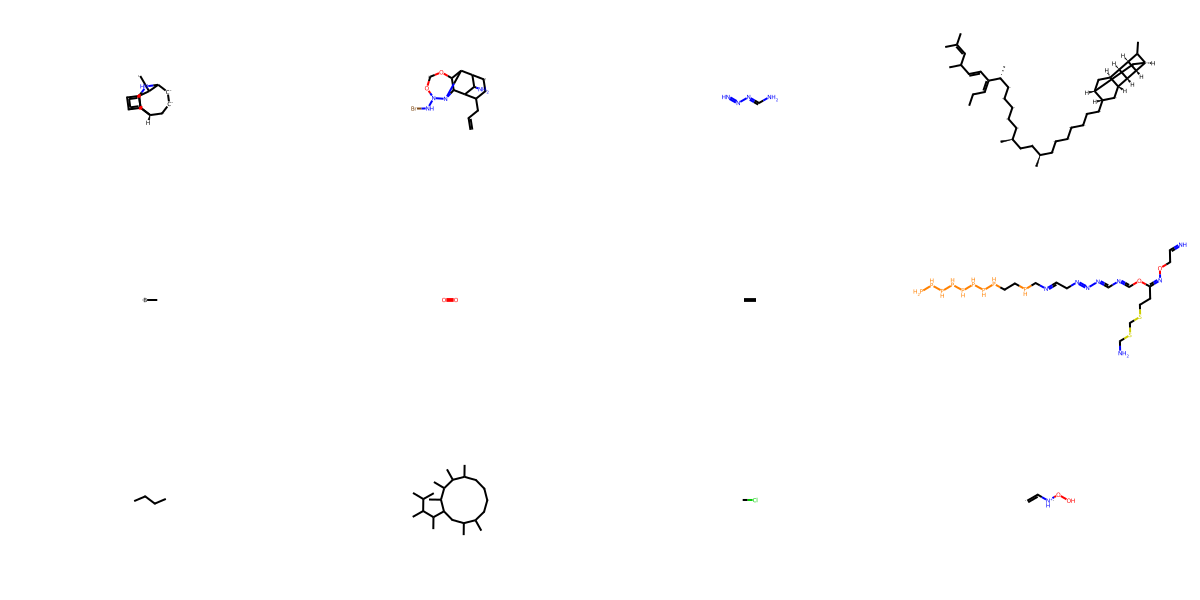

In [6]:
def chemical_summary(decoded, label):
    rows = []
    for smi in decoded:
        valid, canonical = parse_and_canonical(smi)
        mol = Chem.MolFromSmiles(canonical) if valid else None
        rows.append({
            "space": label,
            "smiles": smi,
            "canonical": canonical,
            "valid": valid,
            "acyclic": bool(mol is not None and generic_scaffold_hash(canonical) == "acyclic"),
            "mw": Descriptors.MolWt(mol) if mol else np.nan,
            "heavy_atoms": mol.GetNumHeavyAtoms() if mol else np.nan,
            "rings": Descriptors.RingCount(mol) if mol else np.nan,
            "hetero_atoms": sum(a.GetAtomicNum() not in (1, 6) for a in mol.GetAtoms()) if mol else np.nan,
        })
    return pd.DataFrame(rows)

def sample_and_decode(model, dim, scales, n=1000, prefix="sample"):
    parts = []
    for scale in scales:
        z = sample_latent(n, dim, scale=scale, seed=SEED + int(scale * 100))
        decoded = model.decode(z, batch_size=256)
        part = chemical_summary(decoded, prefix)
        part["scale"] = scale
        parts.append(part)
        clear_gpu()
    return pd.concat(parts, ignore_index=True)

scales = [0.25, 0.5, 1.0, 1.5, 2.0, 3.0, 5.0]
_, prior_load, prior_save = cacher("i1_01_prior_samples")
prior = prior_load()
if prior is None:
    prior = pd.concat([
        sample_and_decode(native, native.latent_dim, scales, prefix="native"),
        sample_and_decode(projected, projected.latent_dim, scales, prefix="pca"),
    ], ignore_index=True)
    prior_save(prior)

prior_summary = (prior.groupby(["space", "scale"]).agg(
    n=("valid", "size"), validity=("valid", "mean"),
    unique=("canonical", "nunique"), acyclic=("acyclic", "mean"),
    median_mw=("mw", "median"), median_heavy=("heavy_atoms", "median"),
).reset_index())
prior_summary["uniqueness"] = prior_summary.unique / prior_summary.n
display(prior_summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for space, group in prior.groupby("space"):
    summary = group.groupby("scale")["valid"].mean()
    axes[0].plot(summary.index, summary.values, "o-", label=space)
    unique = group[group.valid].groupby("scale")["canonical"].nunique() / group.groupby("scale").size()
    axes[1].plot(unique.index, unique.values, "o-", label=space)
for ax, title in zip(axes, ["Validity vs prior scale", "Canonical uniqueness vs prior scale"]):
    ax.set_xscale("log"); ax.set_ylim(-0.05, 1.05); ax.set_title(title); ax.set_xlabel("scale"); ax.legend()
plt.tight_layout(); plt.show()

display(mol_grid(prior[(prior.space == "native") & (prior.scale == 5.0) & prior.valid].sample(12, random_state=SEED).canonical.tolist(), mols_per_row=4))

Going beyond 1.0 on scale creates very weird and impractical molecules. However, as long as we don't do that, chembed seems mostly robust. Check their paper for more detailed information.

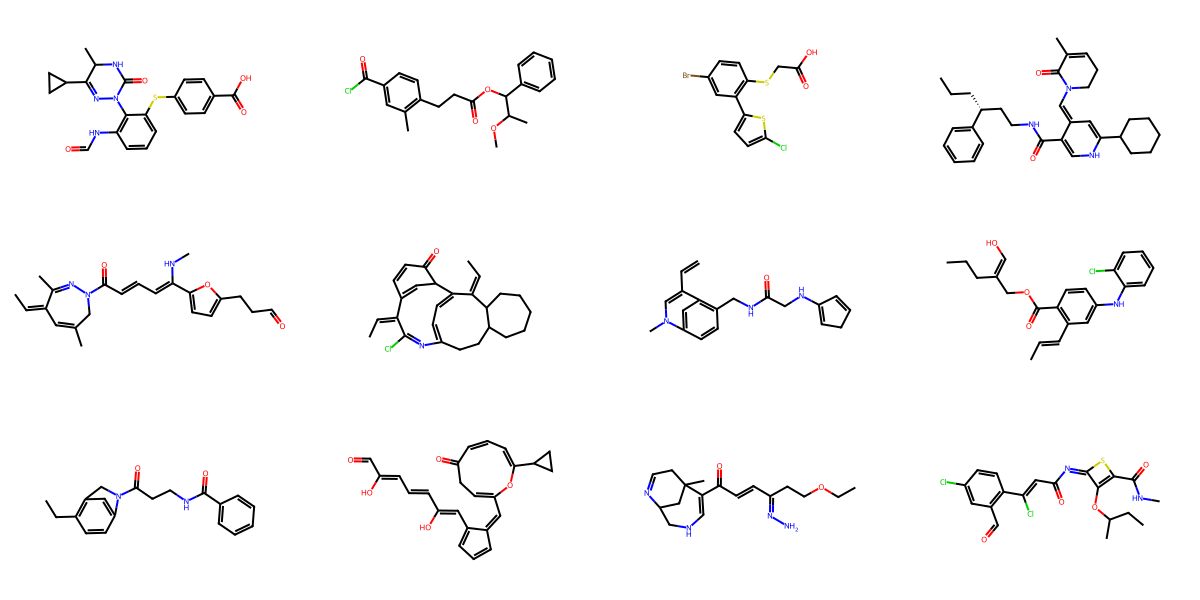

In [7]:
display(mol_grid(prior[(prior.space == "pca") & (prior.scale == 1.0) & prior.valid].sample(12, random_state=SEED).canonical.tolist(), mols_per_row=4))

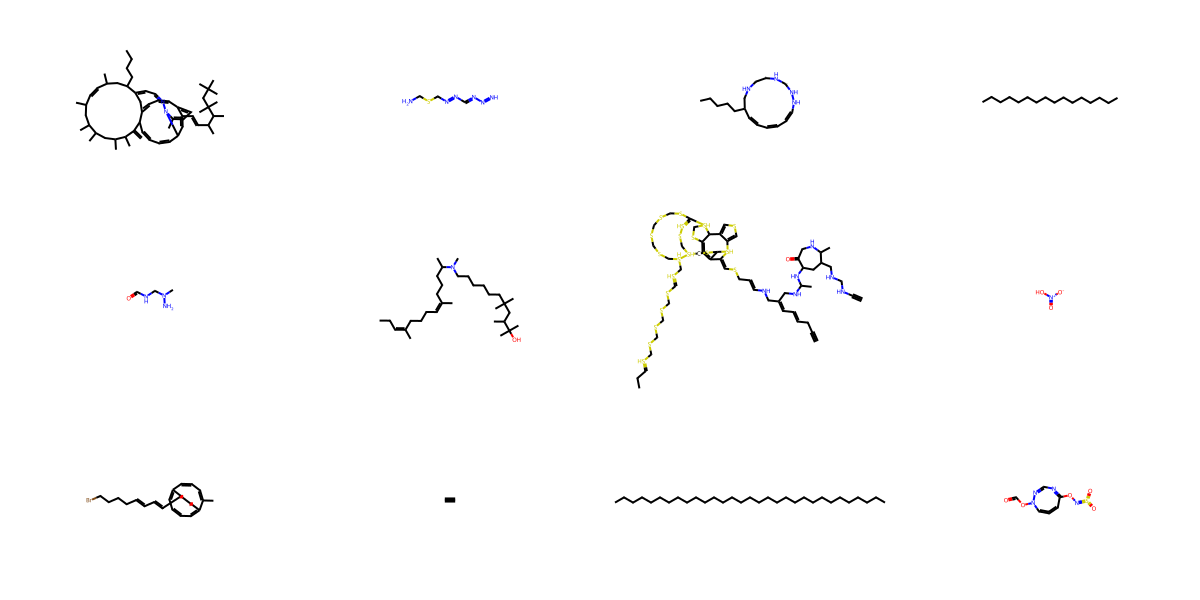

In [8]:
display(mol_grid(prior[(prior.space == "pca") & (prior.scale == 5.0) & prior.valid].sample(12, random_state=SEED).canonical.tolist(), mols_per_row=4))